# Radiaition
- Figure 7

In [ ]:
ref_exp = "iconml_amip_2mom_reference"
SDN_exp = "iconml_amip_superdropnet_sharma25_60s"
DATA_DIR = "/work/ka1176/paul/realistic-superdropnet/data/"

In [2]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sn

In [3]:
dayslice= slice('2020-01-17', '2020-01-22T00:00:00.000000000')


In [4]:
atm_2d_P1D_ref = xr.open_dataset(DATA_DIR + f"/{ref_exp}_atm_2d_P1D_radiation_01deg.nc").sel(time=dayslice)
atm_2d_P1D_SDN = xr.open_dataset(DATA_DIR + f"/{SDN_exp}_atm_2d_P1D_radiation_01deg.nc").sel(time=dayslice)


In [5]:
atm_2d_P1D_diff = atm_2d_P1D_SDN - atm_2d_P1D_ref
atm_2d_P1D_diff_timemean = atm_2d_P1D_diff.mean("time")
atm_2d_P1D_diff_timemean_lonmean = atm_2d_P1D_diff_timemean.mean("lon")
atm_2d_P1D_diff_timemean_coarse = atm_2d_P1D_diff_timemean.coarsen(lon=10,lat=10).mean(["lon","lat"])

In [8]:
surface_vars = ["rlds", "rlus", "rsds", "rsus"]
TOA_vars = ["rlut", "rsut"]

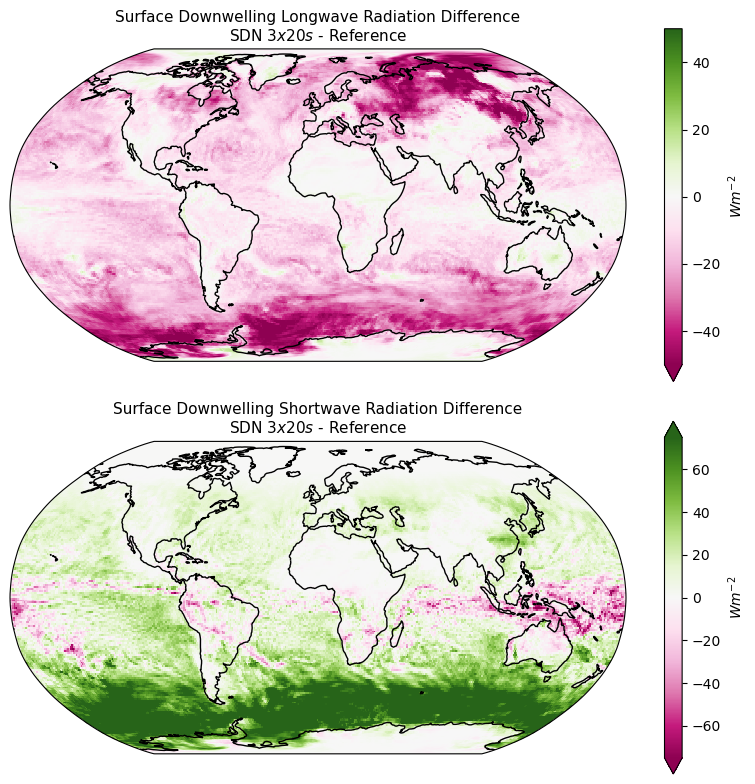

In [35]:
fig, axes = plt.subplots(2,1,figsize=(8, 8), subplot_kw={'projection': ccrs.Robinson()})

#sn.despine(fig =fig)
axes=axes.flatten()

i=0
im = atm_2d_P1D_diff_timemean_coarse["rlds"].plot(x="lon", y="lat", ax = axes[i], cmap="PiYG", transform=ccrs.PlateCarree(), vmin=-50, vmax=50 )
axes[i].coastlines()
axes[i].set_title(r"Surface Downwelling Longwave Radiation Difference"
                "\n"
                "SDN $3x20s$ - Reference", size=11)
im.colorbar.set_label("$Wm^{-2}$")

i=1
im = atm_2d_P1D_diff_timemean_coarse["rsds"].plot(x="lon", y="lat", ax = axes[i], cmap="PiYG", transform=ccrs.PlateCarree(), vmin=-75, vmax=75 )
axes[i].coastlines()
axes[i].set_title("Surface Downwelling Shortwave Radiation Difference"
                "\n"
                "SDN $3x20s$ - Reference", size=11)
im.colorbar.set_label("$Wm^{-2}$")
#plt.legend(frameon=False)


plt.tight_layout()

fig.savefig("../plots/surface_radiation.png")